## RESEARCH QUESTION:

Can machine learning models predict the outcome of a Dota 2 match using hero composition and early-game team performance? 

#### DATA SET INFORMATION:

I got my data set from Kaggle - Dota 2: Predicting match outcome. Source: https://www.kaggle.com/competitions/dota-2-prediction/data

In [132]:
#Data set upload

import pandas as pd

train_df = pd.read_csv("train.csv", low_memory=False)
test_df = pd.read_csv("test.csv", low_memory=False)

print("Train shape:", train_df.shape)
print("Test shape:", test_df.shape)

Train shape: (409794, 103)
Test shape: (71772, 102)


In [133]:
#Data set information
train_df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 409794 entries, 0 to 409793
Columns: 103 entries, match_id to radiant_win
dtypes: float64(12), int64(90), object(1)
memory usage: 322.0+ MB


In [134]:
train_df.head()

,match_id,r1_hero,r1_level,r1_xp,r1_gold,r1_lh,r1_kills,r1_deaths,r1_items,r2_hero,...,dire_bottle_time,dire_courier_time,dire_flying_courier_time,dire_tpscroll_count,dire_boots_count,dire_ward_observer_count,dire_ward_sentry_count,dire_first_ward_time,duration,radiant_win
0,1956782143,106,3,2060,1864,28,0,7,6,8,...,144.0,-71.0,184.0,2,2,2,1,32.0,4001,True
1,1956782359,112,0,747,1117,0,0,8,13,50,...,135.0,-81.0,294.0,7,1,3,0,-24.0,2628,True
2,1956782465,46,2,1839,1477,13,1,0,10,6,...,48.0,-72.0,219.0,4,2,2,0,-20.0,1721,True
3,1956782479,35,0,1681,1312,14,1,12,8,75,...,125.0,-87.0,209.0,3,5,3,0,35.0,1965,False
4,1956783553,68,0,445,613,3,0,9,6,107,...,97.0,-84.0,NaN,3,3,2,0,-42.0,2522,False


There are 5 radiant (r1...r5) and 5 dire (d1....d5) players in each match. Early player's performance is measured by the following variables: level (level a player has reached), xp (experience points), gold (game currency to purchase items), lh (last hit), kills, deaths for each player. Early team performance can be measured by first_blood_time, first_blood_team, radiant_first_ward_time, dire_first_ward_time, radiant_bottle_time, dire_bottle_time, radiant_courier_time, dire_courier_time. My variable of interest is radiant_win which is a boolean variable of True or False.

In [136]:
train_df.describe()

,match_id,r1_hero,r1_level,r1_xp,r1_gold,r1_lh,r1_kills,r1_deaths,r1_items,r2_hero,...,radiant_first_ward_time,dire_bottle_time,dire_courier_time,dire_flying_courier_time,dire_tpscroll_count,dire_boots_count,dire_ward_observer_count,dire_ward_sentry_count,dire_first_ward_time,duration
count,4.097940e+05,409794.000000,409794.000000,409794.000000,409794.000000,409794.000000,409794.000000,409794.000000,409794.000000,409794.000000,...,368216.000000,315948.000000,402634.000000,226615.000000,409794.000000,409794.000000,409794.000000,409794.000000,365951.000000,409794.000000
mean,1.979152e+09,51.261034,0.625807,1267.234450,1148.777388,10.852206,0.393354,6.260821,7.936841,51.361643,...,11.680815,120.596348,-66.249899,220.404007,2.928796,3.225743,1.945817,0.334175,11.514984,2495.798843
std,1.277888e+07,33.189960,0.786031,505.016573,428.227612,8.041734,0.695038,3.945948,2.560414,33.233699,...,55.194283,75.506567,36.373922,35.860592,1.868018,1.139206,0.971057,0.614921,57.558441,640.847785
min,1.956782e+09,1.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,1.000000,...,-291.000000,-88.000000,-90.000000,180.000000,0.000000,0.000000,0.000000,0.000000,-293.000000,1200.000000
25%,1.968194e+09,21.000000,0.000000,894.000000,817.000000,4.000000,0.000000,3.000000,6.000000,21.000000,...,-21.000000,76.000000,-83.000000,188.000000,2.000000,2.000000,2.000000,0.000000,-22.000000,2029.000000
50%,1.979570e+09,49.000000,0.000000,1180.000000,1105.000000,10.000000,0.000000,6.000000,8.000000,49.000000,...,0.000000,129.000000,-74.000000,210.000000,3.000000,3.000000,2.000000,0.000000,-3.000000,2430.000000
75%,1.989660e+09,75.000000,1.000000,1648.000000,1421.000000,17.000000,1.000000,9.000000,10.000000,76.000000,...,21.000000,167.000000,-63.000000,248.000000,4.000000,4.000000,2.000000,1.000000,20.000000,2895.000000
max,2.001394e+09,112.000000,5.000000,3470.000000,4616.000000,51.000000,8.000000,52.000000,44.000000,112.000000,...,300.000000,300.000000,300.000000,300.000000,25.000000,8.000000,17.000000,36.000000,300.000000,7479.000000


#### DATA SET EXPLORATION:

In [137]:
# Let's look at the percentage of radiant win and lose
counts = train_df["radiant_win"].value_counts()

percentages = train_df["radiant_win"].value_counts(normalize=True) * 100

# Create a data frame with counts and percentages
outcome_summary = pd.DataFrame({
    "Count": counts,
    "Percentage": percentages.round(2)
})

print(outcome_summary)

              Count  Percentage
radiant_win                    
True         212112       51.76
False        197674       48.24


Our variable of interest has a good balance of radiant_win = True (having appr 52%) and radiant_win = False (having 48% of the total data set).

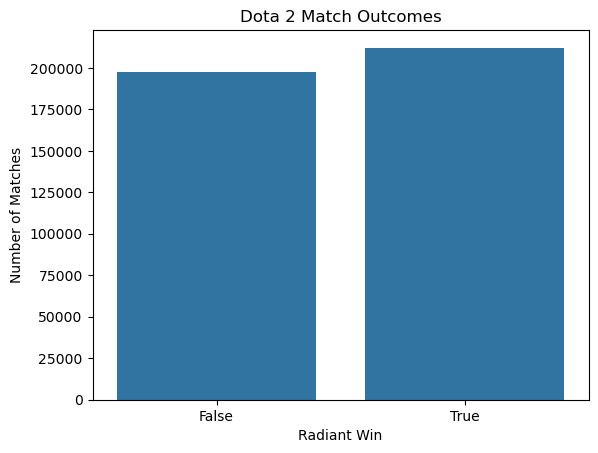

In [138]:
#Bar graph of radiant win versus loss.
import matplotlib.pyplot as plt
import seaborn as sns

sns.countplot(data=train_df, x="radiant_win")
plt.title("Dota 2 Match Outcomes")
plt.xlabel("Radiant Win")
plt.ylabel("Number of Matches")
plt.show()

#### Missing Data Analysis:

In [139]:
# Missing data analysis: count and percentage
missing_summary = pd.DataFrame({
    "Missing Count": train_df.isnull().sum(),
    "Missing Percentage": train_df.isnull().mean() * 100
})

missing_summary = missing_summary[missing_summary["Missing Count"] > 0]
missing_summary = missing_summary.sort_values(
    "Missing Percentage", ascending=False
)

missing_summary

,Missing Count,Missing Percentage
radiant_flying_courier_time,189842,46.326203
dire_flying_courier_time,183179,44.700264
dire_bottle_time,93846,22.900775
radiant_bottle_time,91593,22.350986
dire_first_ward_time,43843,10.698790
radiant_first_ward_time,41578,10.146073
first_blood_time,26646,6.502291
first_blood_team,26646,6.502291
first_blood_player1,26646,6.502291
first_blood_player2,26646,6.502291


More than 44% of radiant and dire flying courier time data is missing. 22% of dire and radiant bottle times data is missing. Additionally, 10% of radiant and dire first ward time data is missing. Because it is unclear whether these missing values indicate that the items were not acquired or that the data was not collected, I will exclude these variables from the analysis. On the other hand, the Kaggle Dota 2 dataset documentation explains that if the first-blood event does not occur within the first five minutes, the corresponding columns contain missing values. Therefore, I will keep first_blood_time and first_blood_team in my analysis.

In [140]:
#Let's drop the mentioned columns.
drop_cols = [
    "radiant_flying_courier_time",
    "dire_flying_courier_time",
    "radiant_bottle_time",
    "dire_bottle_time",
    "radiant_first_ward_time",
    "dire_first_ward_time"
]

train_df = train_df.drop(columns=drop_cols)

Let's remove 8 missing rows for radiant_win variable.

In [141]:
train_df = train_df.dropna(subset=["radiant_win"])

In [142]:
# Let's see if there are any duplicates in the data set.

# Check duplicate column names
print("Duplicate column names:")
print(train_df.columns[train_df.columns.duplicated()])

# Check whether all match IDs are unique
print(train_df["match_id"].is_unique)

Duplicate column names:
Index([], dtype='object')
True


There are no duplicate columns and all match id's are unique.

#### Distribution of early game team performance - Total kills versus wins

In [143]:
#Let's create a early radiant total kill variable
train_df["radiant_total_kills"] = train_df[
    ["r1_kills", "r2_kills", "r3_kills", "r4_kills", "r5_kills"]
].sum(axis=1)

#Let's create a early dire total kill variable
train_df["dire_total_kills"] = train_df[
    ["d1_kills", "d2_kills", "d3_kills", "d4_kills", "d5_kills"]
].sum(axis=1)

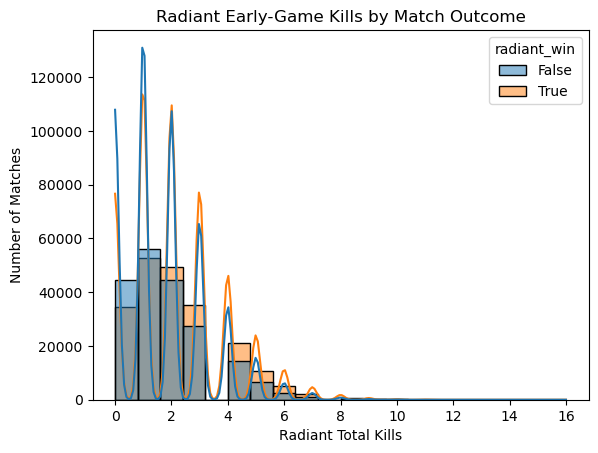

In [144]:
# Let's plot total radiant total kills versus wins
sns.histplot(data=train_df, x="radiant_total_kills", hue="radiant_win",
             bins=20, kde=True)
plt.title("Radiant Early-Game Kills by Match Outcome")
plt.xlabel("Radiant Total Kills")
plt.ylabel("Number of Matches")
plt.show()

Higher radiant early game total kills is associated with higher wins.

#### Distribution of early game gold advantage vs. Total wins

In [145]:
#Let's create an early radiant total gold variable
train_df["radiant_total_gold"] = train_df[
    ["r1_gold", "r2_gold", "r3_gold", "r4_gold", "r5_gold"]
].sum(axis=1)

#Let's create an early dire total gold variable
train_df["dire_total_gold"] = train_df[
    ["d1_gold", "d2_gold", "d3_gold", "d4_gold", "d5_gold"]
].sum(axis=1)

#Radiant gold advantage - Take the difference between radiant total gold and dire total gold
train_df["gold_difference"] = (
    train_df["radiant_total_gold"] - train_df["dire_total_gold"]
)

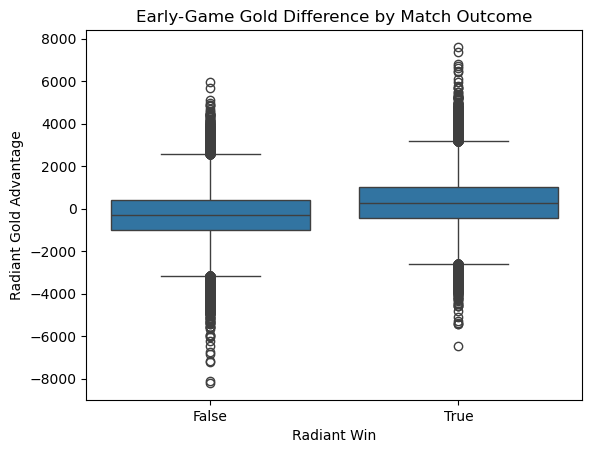

In [146]:
# Box plot of early game gold difference by match outcome
sns.boxplot(data=train_df, x="radiant_win", y="gold_difference")
plt.title("Early-Game Gold Difference by Match Outcome")
plt.xlabel("Radiant Win")
plt.ylabel("Radiant Gold Advantage")
plt.show()

We see from above plot that higher radiant gold advantage is associated with radiant wins.

#### Team experience (XP) points advantage versus match outcome

In [147]:
#Let's create a early radiant xp points variable
train_df["radiant_total_xp"] = train_df[
    ["r1_xp", "r2_xp", "r3_xp", "r4_xp", "r5_xp"]
].sum(axis=1)

#Let's create a early dire xp points variable
train_df["dire_total_xp"] = train_df[
    ["d1_xp", "d2_xp", "d3_xp", "d4_xp", "d5_xp"]
].sum(axis=1)

#Radiant xp advantage points - Take the difference between radiant xp and dire xp points
train_df["xp_difference"] = (
    train_df["radiant_total_xp"] - train_df["dire_total_xp"]
)

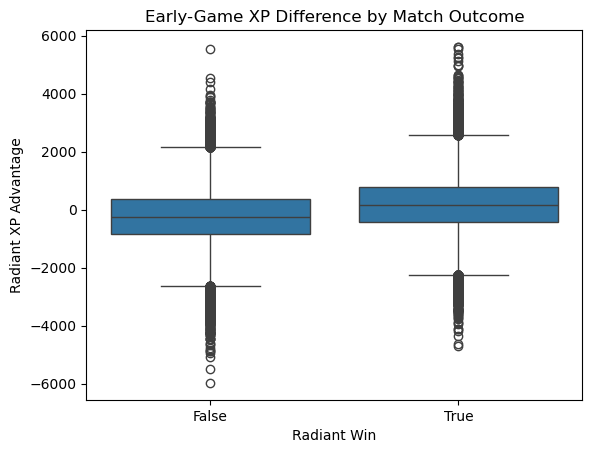

In [148]:
# Box plot of early game gold difference by match outcome
sns.boxplot(data=train_df, x="radiant_win", y="xp_difference")
plt.title("Early-Game XP Difference by Match Outcome")
plt.xlabel("Radiant Win")
plt.ylabel("Radiant XP Advantage")
plt.show()

Higher early game radiant experience advantage is associated with higher radiant wins.

#### First blood team and match outcome

From Kaggle DOTA 2 data set:
first_blood_team is the team that committed the first blood (0 - Radiant, 1 - Dire). Let's look at the association between radiant first blood and their win percentage.

In [149]:
#Lets create a table with first_blood_team and radiant_win percentage
pd.crosstab(
    train_df["first_blood_team"],
    train_df["radiant_win"],
    normalize="index"
) * 100

radiant_win,False,True
first_blood_team,,
0.0,42.720195,57.279805
1.0,53.624014,46.375986


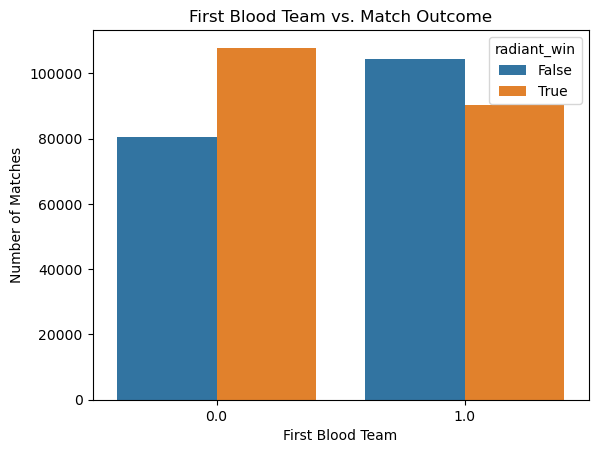

In [150]:
#Plot the relationship
sns.countplot(data=train_df, x="first_blood_team", hue="radiant_win")
plt.title("First Blood Team vs. Match Outcome")
plt.xlabel("First Blood Team")
plt.ylabel("Number of Matches")
plt.show()

The plot suggests that Radiant won 57% of games when they performed first blood. Dire has won 53% of the games when Dire performed first bood. There is a positive association between first blood team and win.

#### Early game last hit advantage versus outcome

In [151]:
#Let's create radiant total last hit variable
train_df["radiant_total_lh"] = train_df[
    ["r1_lh", "r2_lh", "r3_lh", "r4_lh", "r5_lh"]
].sum(axis=1)

#Let's create dire total last hit variable
train_df["dire_total_lh"] = train_df[
    ["d1_lh", "d2_lh", "d3_lh", "d4_lh", "d5_lh"]
].sum(axis=1)

# Radiant last hit difference
train_df["lh_difference"] = (
    train_df["radiant_total_lh"] - train_df["dire_total_lh"]
)

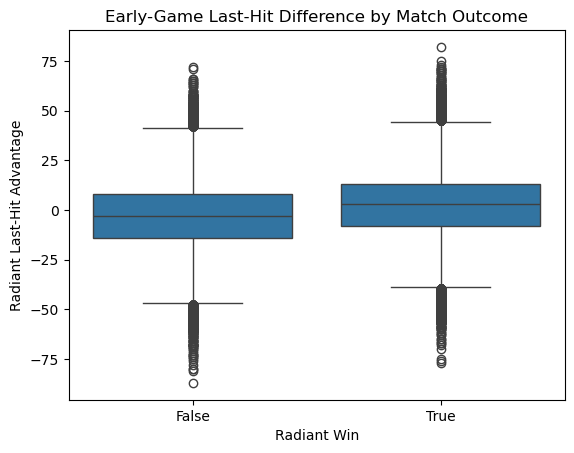

In [152]:
# Box plot of radiant last hit difference by match outcome
sns.boxplot(data=train_df, x="radiant_win", y="lh_difference")
plt.title("Early-Game Last-Hit Difference by Match Outcome")
plt.xlabel("Radiant Win")
plt.ylabel("Radiant Last-Hit Advantage")
plt.show()

Box plot suggest that higher early game radiant last hit advantage is associated with higher radiant win.

#### Correlation heatmap of team features

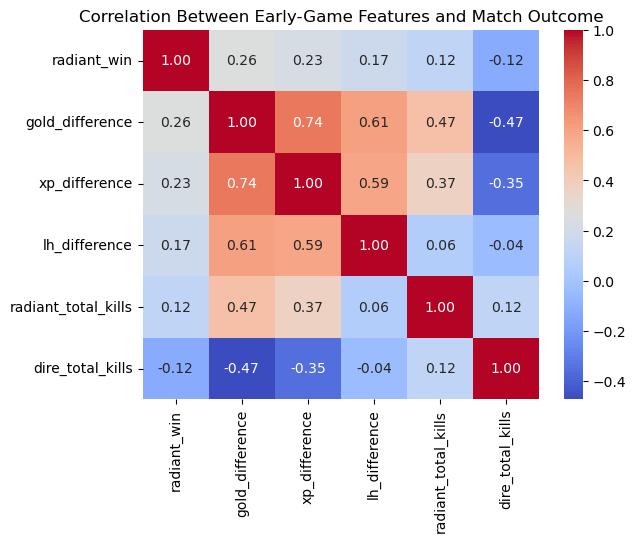

In [153]:
corr_cols = [
    "radiant_win",
    "gold_difference",
    "xp_difference",
    "lh_difference",
    "radiant_total_kills",
    "dire_total_kills"
]

sns.heatmap(
    train_df[corr_cols].corr(),
    annot=True,
    cmap="coolwarm",
    fmt=".2f"
)

plt.title("Correlation Between Early-Game Features and Match Outcome")
plt.show()

Radiant gold advantage is highly correlated with radiant experience point advantage and radiant last hit advantage. Radiant last hit advantage is highly correlated with radiant experience point advantage. Additionally, radiant total kills is moderately correlated with radiant gold advantage.

#### Let's look at most picked heros and hero win rate:

In [154]:
# Selecting radiant and dire hero columns only from the data set.
radiant_hero_cols = [f"r{i}_hero" for i in range(1, 6)]
dire_hero_cols = [f"d{i}_hero" for i in range(1, 6)]

hero_cols = radiant_hero_cols + dire_hero_cols

hero_cols

['r1_hero',
 'r2_hero',
 'r3_hero',
 'r4_hero',
 'r5_hero',
 'd1_hero',
 'd2_hero',
 'd3_hero',
 'd4_hero',
 'd5_hero']

In [155]:
# Creating a dataset of all heros with their occurances.
hero_picks = pd.concat(
    [train_df[col] for col in hero_cols],
    ignore_index=True
)

hero_pick_counts = hero_picks.value_counts()

# Displays top 10 picked hero
hero_pick_counts.head(10)

11     131224
21     130483
74     100659
106     90483
7       89485
8       87615
100     86221
50      80173
14      78479
28      76883
Name: count, dtype: int64

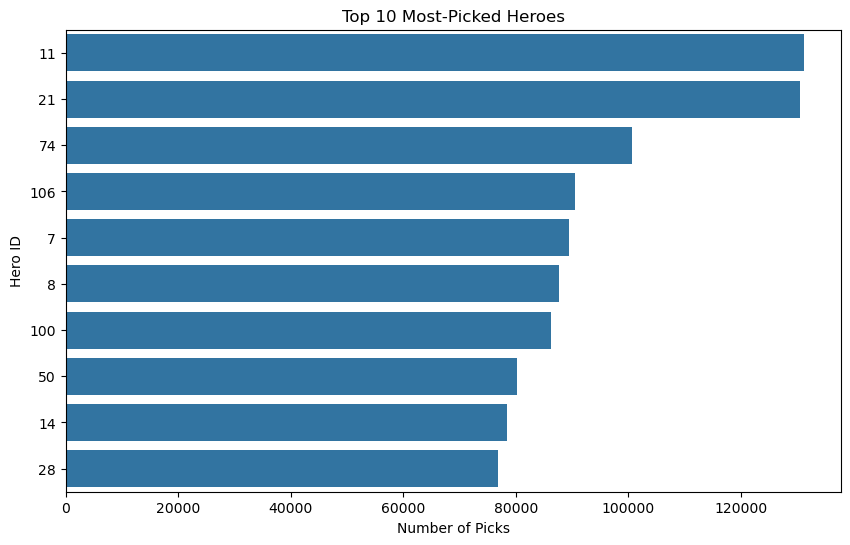

In [156]:
# Bar plotting the most picked heros.
top_10_picked = hero_pick_counts.head(10)

plt.figure(figsize=(10, 6))

sns.barplot(
    x=top_10_picked.values,
    y=top_10_picked.index.astype(str)
)

plt.title("Top 10 Most-Picked Heroes")
plt.xlabel("Number of Picks")
plt.ylabel("Hero ID")
plt.show()

Hero id 11 and 21 was picked the most by the players.

I will look at heros with highest win rate and their associated pick value.

In [157]:
# Radiant hero
# Create a new data frame with each radiant hero and corresponding radiant_win
radiant_long = train_df[radiant_hero_cols + ["radiant_win"]].melt(
    id_vars="radiant_win",
    value_name="hero"
)

# Create a new column called hero_win 0 or 1.
radiant_long["hero_win"] = (
    radiant_long["radiant_win"] == True
).astype(int)


# Dire heroes
# Create a new data frame with each dire hero and corresponding dire_win
dire_long = train_df[dire_hero_cols + ["radiant_win"]].melt(
    id_vars="radiant_win",
    value_name="hero"
)

# Create a new column called hero_win 0 or 1.
# Dire hero wins when Radiant loses
dire_long["hero_win"] = (
    dire_long["radiant_win"] == False
).astype(int)


# Combine radiant and dire data
hero_results = pd.concat(
    [
        radiant_long[["hero", "hero_win"]],
        dire_long[["hero", "hero_win"]]
    ],
    ignore_index=True
)


# Calculate hero picks and win rate
hero_win_rate = (
    hero_results
    .groupby("hero")["hero_win"]
    .agg(["count", "mean"])
    .rename(columns={
        "count": "picks",
        "mean": "win_rate"
    })
)

hero_win_rate["win_rate"] = hero_win_rate["win_rate"] * 100

In [158]:
hero_win_rate.sort_values("win_rate", ascending=False).head(10)

,picks,win_rate
hero,,
57,37310,59.171804
102,30554,57.976042
67,39854,57.954032
42,55526,56.908475
36,43519,56.805074
70,35521,56.718561
32,38538,56.219835
31,38148,55.767013
22,36262,55.636755


Hero 57 had the highest observed win rate among the heroes in the dataset, with a 59.17% win rate across 37,310 picks.

I will look at the association of hero win rate and pick percentage.

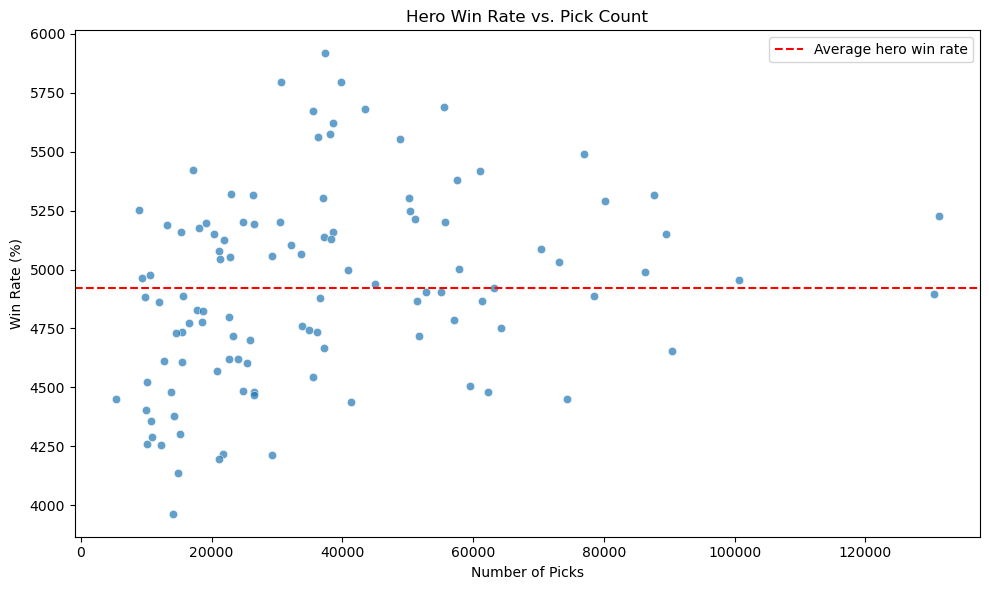

In [160]:
# Convert win rate from decimal to percentage
hero_win_rate["win_rate_pct"] = hero_win_rate["win_rate"] * 100

# Create scatter plot
plt.figure(figsize=(10, 6))

sns.scatterplot(
    data=hero_win_rate,
    x="picks",
    y="win_rate_pct",
    alpha=0.7
)

# Show the average hero win rate
plt.axhline(
    y=hero_win_rate["win_rate_pct"].mean(),
    color="red",
    linestyle="--",
    label="Average hero win rate"
)

plt.title("Hero Win Rate vs. Pick Count")
plt.xlabel("Number of Picks")
plt.ylabel("Win Rate (%)")
plt.legend()
plt.tight_layout()
plt.show()

#### Outlier analysis:

Radiant kill advantage is also another team performance variable, so I will first create that data.

In [161]:
train_df["kill_difference"] = (
    train_df["radiant_total_kills"] -
    train_df["dire_total_kills"]
)


In [162]:
# Defining performance features.
performance_features = [
    "gold_difference",
    "xp_difference",
    "lh_difference",
    "kill_difference"
]

Here is plotting outliers in early game performance features.

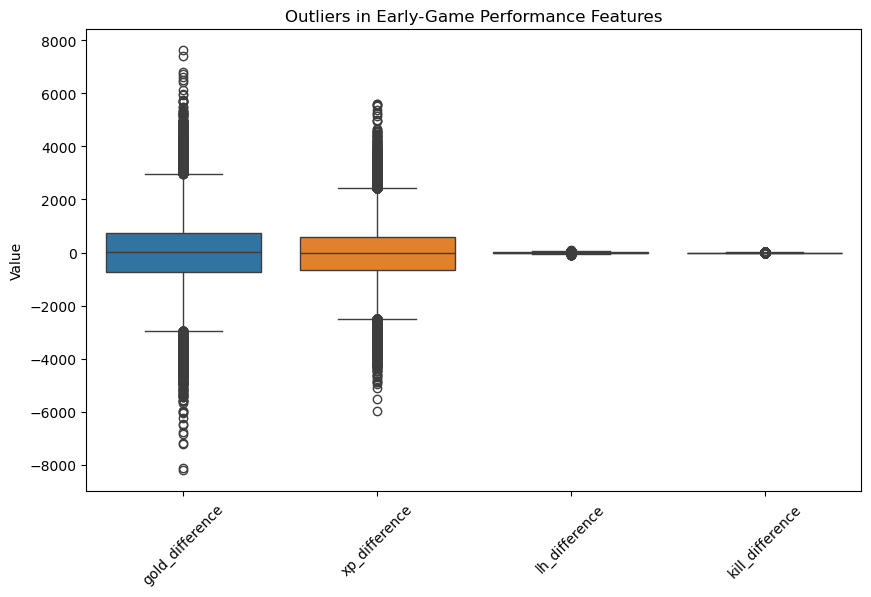

In [163]:
import matplotlib.pyplot as plt
import seaborn as sns

plt.figure(figsize=(10, 6))

sns.boxplot(data=train_df[performance_features])

plt.title("Outliers in Early-Game Performance Features")
plt.ylabel("Value")
plt.xticks(rotation=45)
plt.show()

In [164]:
for col in performance_features:
    Q1 = train_df[col].quantile(0.25)
    Q3 = train_df[col].quantile(0.75)
    
    IQR = Q3 - Q1
    
    lower_bound = Q1 - 1.5 * IQR
    upper_bound = Q3 + 1.5 * IQR
    
    outliers = train_df[
        (train_df[col] < lower_bound) |
        (train_df[col] > upper_bound)
    ]
    
    print(f"{col}: {len(outliers)} outliers")

gold_difference: 4471 outliers
xp_difference: 4328 outliers
lh_difference: 2816 outliers
kill_difference: 16874 outliers


### Modeling:

In [165]:
# Lets look at the test data columns.
test_df.head()

,match_id,r1_hero,r1_level,r1_xp,r1_gold,r1_lh,r1_kills,r1_deaths,r1_items,r2_hero,...,radiant_first_ward_time,dire_bottle_time,dire_courier_time,dire_flying_courier_time,dire_tpscroll_count,dire_boots_count,dire_ward_observer_count,dire_ward_sentry_count,dire_first_ward_time,duration
0,1,18,0,1649,1239,17,0,4,5,25,...,14.0,166.0,-77.0,278.0,3,5,2,0,-30.0,2729
1,2,86,1,1175,743,6,0,8,11,23,...,-11.0,4.0,NaN,NaN,0,4,1,0,NaN,2511
2,3,47,1,2391,1556,16,1,12,12,2,...,38.0,39.0,-71.0,181.0,2,4,3,0,-23.0,1776
3,4,74,0,1810,1203,17,0,4,6,97,...,14.0,80.0,-84.0,NaN,3,3,2,0,-16.0,2239
4,5,106,0,1918,1312,16,0,9,8,69,...,-4.0,94.0,-84.0,NaN,3,3,2,1,-36.0,4027


Test data set doesn't have target variable radiant_win. Therefore we can't have y_test data. We should use cross-validation on train_df to evaluate the baseline model.

I need to create early game performance variables for test data as well. I will create radiant gold, experience points, last hit, and kills advantage variables.

In [166]:
# Radiant totals
test_df["radiant_total_gold"] = sum(
    test_df[f"r{i}_gold"] for i in range(1, 6)
)

test_df["radiant_total_xp"] = sum(
    test_df[f"r{i}_xp"] for i in range(1, 6)
)

test_df["radiant_total_lh"] = sum(
    test_df[f"r{i}_lh"] for i in range(1, 6)
)

test_df["radiant_total_kills"] = sum(
    test_df[f"r{i}_kills"] for i in range(1, 6)
)

In [167]:
# Dire totals
test_df["dire_total_gold"] = sum(
    test_df[f"d{i}_gold"] for i in range(1, 6)
)

test_df["dire_total_xp"] = sum(
    test_df[f"d{i}_xp"] for i in range(1, 6)
)

test_df["dire_total_lh"] = sum(
    test_df[f"d{i}_lh"] for i in range(1, 6)
)

test_df["dire_total_kills"] = sum(
    test_df[f"d{i}_kills"] for i in range(1, 6)
)

In [168]:
# Radiant gold advantage 
test_df["gold_difference"] = (
    test_df["radiant_total_gold"] - test_df["dire_total_gold"]
)

# Radiant xp advantage
test_df["xp_difference"] = (
    test_df["radiant_total_xp"] - test_df["dire_total_xp"]
)

# Radiant last hit advantage
test_df["lh_difference"] = (
    test_df["radiant_total_lh"] - test_df["dire_total_lh"]
)

# Radiant kill difference advantage in test data
test_df["kill_difference"] = (
    test_df["radiant_total_kills"] - test_df["dire_total_kills"]
)

In [169]:
performance_features = [
    "gold_difference",
    "xp_difference",
    "lh_difference",
    "kill_difference"
]

In [170]:
X_train = train_df[performance_features]
y_train = train_df["radiant_win"].astype(int)

X_test = test_df[performance_features]

Target variable, radiant_win is a binary variable. Therefore, I will use a logistic regression model. To evaluate model performance reliably, I will use five-fold stratified cross-validation (StratifiedKFold). This method divides the dataset into five folds while maintaining approximately the same proportion of Radiant wins and losses in each fold. In each iteration, four folds are used to train the model, and the remaining fold is used to evaluate its performance. This process is repeated five times, with each fold serving as the validation set once. I will calculate the mean accuracy across the five folds to estimate the model's predictive performance.

In [171]:
from sklearn.model_selection import StratifiedKFold, cross_val_score
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression

# Create a shuffled StratifiedKFold object
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)

# Build the first model using early-game performance features
logistic_pipeline = make_pipeline(
    StandardScaler(),
    LogisticRegression(max_iter=1000)
)

# Evaluate the model using 5-fold cross-validation
scores = cross_val_score(
    logistic_pipeline,
    X_train,
    y_train,
    cv=cv,
    scoring="accuracy"
)

print("Mean Accuracy:", scores.mean())
print("Cross-validation scores:", scores)

Mean Accuracy: 0.6093863666305229
Cross-validation scores: [0.60775031 0.60889247 0.61045426 0.61039325 0.60944154]


The logistic regression baseline achieved a mean five-fold cross-validation accuracy of approximately 60.93% using four early-game performance features: gold difference, XP difference, last-hit difference, and kill difference. This is approximately 9.17 percentage points higher than the majority-class baseline of 51.76%. These results suggest that early-game team performance contains useful information for predicting match outcomes, although the model's predictive performance remains limited. Further experiments are needed to determine whether incorporating hero composition improves accuracy.

#### Modeling Match Outcomes Using Hero Composition

The hero selections are represented by r1–r5 for radiant and d1–d5 for dire in my data set.
I will be using one-hot encoding to represent the selected heroes as categorical features, then train a logistic regression classifier.

In [172]:
from sklearn.preprocessing import OneHotEncoder
from sklearn.impute import SimpleImputer

# Select the 10 hero features
hero_selection = [
    "r1_hero", "r2_hero", "r3_hero", "r4_hero", "r5_hero",
    "d1_hero", "d2_hero", "d3_hero", "d4_hero", "d5_hero"
]

X_hero = train_df[hero_selection]
y = train_df["radiant_win"].astype(int)

# Preprocessing and classification pipeline
hero_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("encoder", OneHotEncoder(handle_unknown="ignore")),
    ("classifier", LogisticRegression(max_iter=1000))
])

# Use the same cross-validation strategy as the combined model
cv = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

hero_scores = cross_val_score(
    hero_pipeline,
    X_hero,
    y,
    cv=cv,
    scoring="accuracy",
    n_jobs=-1
)

print("Hero Composition Model Accuracy:", hero_scores.mean())
print("Cross-validation scores:", hero_scores)

Hero Composition Model Accuracy: 0.5962209600708863
Cross-validation scores: [0.59387735 0.59562942 0.5995461  0.59621509 0.59583684]


The model achieved a mean accuracy of 59.62%, with fold-level accuracies ranging from 59.38% to 59.95%. This is approximately 7.86 percentage points higher than the majority-class baseline of 51.76%.

These results suggest that hero composition provides useful information for predicting match outcomes. However, hero selections alone do not fully explain the outcome of a match. The next step is to use early game performance and hero selection variables together to predict match outcomes.

#### Incorporate both hero composition and early game performance to explain match outcomes

In [173]:
from sklearn.compose import ColumnTransformer


# Combine both feature groups
combined_features = hero_selection + performance_features

X_combined = train_df[combined_features]
y = train_df["radiant_win"].astype(int)

# Preprocess hero and performance features separately
preprocessor = ColumnTransformer(
    transformers=[
        (
            "heroes",
            Pipeline([
                ("imputer", SimpleImputer(strategy="most_frequent")),
                ("encoder", OneHotEncoder(handle_unknown="ignore"))
            ]),
            hero_selection
        ),
        (
            "performance",
            Pipeline([
                ("imputer", SimpleImputer(strategy="median")),
                ("scaler", StandardScaler())
            ]),
            performance_features
        )
    ]
)

# Create the combined logistic regression pipeline
combined_pipeline = Pipeline([
    ("preprocessor", preprocessor),
    ("classifier", LogisticRegression(max_iter=1000))
])

# Evaluate using five-fold stratified cross-validation
cv = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

combined_scores = cross_val_score(
    combined_pipeline,
    X_combined,
    y,
    cv=cv,
    scoring="accuracy",
    n_jobs=-1
)

print("Combined Model Accuracy:", combined_scores.mean())
print("Cross-validation scores:", combined_scores)

Combined Model Accuracy: 0.6522014010543751
Cross-validation scores: [0.64886893 0.65324499 0.65396488 0.65341582 0.65151238]


The combined model achieves 65.22% mean cross-validation accuracy, which is better than the baseline and either feature group used independently.

#### Comparing Three Models:

In [174]:
majority_baseline = y_train.value_counts(normalize=True).max()

accuracy_summary = pd.DataFrame({
    "Model": [
        "Majority-class baseline",
        "Radiant early game performance",
        "Hero composition",
        "Combined model"
    ],
    "Mean Accuracy (%)": [
        majority_baseline * 100,
        scores.mean() * 100,
        hero_scores.mean() * 100,
        combined_scores.mean() * 100
    ]
})

accuracy_summary["Improvement Over Baseline (percentage points)"] = (
    accuracy_summary["Mean Accuracy (%)"] - majority_baseline * 100
)

accuracy_summary = accuracy_summary.round(2)

accuracy_summary

,Model,Mean Accuracy (%),Improvement Over Baseline (percentage points)
0,Majority-class baseline,51.76,0.00
1,Radiant early game performance,60.94,9.18
2,Hero composition,59.62,7.86
3,Combined model,65.22,13.46


The combined model achieved the highest mean accuracy at 65.22%, outperforming the early-game performance model (60.95%) and the hero composition model (59.62%).
These results suggest that combining hero selections with early-game performance provides more predictive information than either feature group alone. The combined model improved mean accuracy by 4.27 percentage points over the early-game performance model and by 5.60 percentage points over the hero composition model.

#### CONCLUSION

This project investigated whether machine learning models can predict Dota 2 match outcomes using hero composition and early-game team performance. I compared three logistic regression models using five-fold cross-validation: a model based on early-game performance, a model based on hero composition, and a combined model using both early-game performance and hero composition.

The early-game performance model achieved a mean accuracy of 60.93%, while the hero composition model achieved 59.62%. The combined model performed best, reaching a mean accuracy of 65.22%. Compared with the majority-class baseline of 51.76%, the combined model improved accuracy by 13.46 percentage points.

These results suggest that combining hero selections with early-game performance provides more predictive information than using either feature group independently. Early-game gold, experience, last-hit, and kill differences provide useful information about match outcomes, while hero composition contributes additional predictive value.